# Task : build an MCP server that exposes external APIs as resources for AI agent.
#### in Phase 3 - Module 6: Model Context Protocol (MCP)
----------
The MCP server should provide metadata about each API and allow dynamic queries.

### Environment Setup & Imports


In [1]:
import os
import requests
from dotenv import load_dotenv
from langchain_core.tools import tool
from mcp.server.fastmcp import FastMCP

load_dotenv()
print("Environment and dependencies initialized successfully.")

Environment and dependencies initialized successfully.


## R1: Use LangChain to wrap each API as a Tool for the agent

### 1.1 OpenWeatherMap Tool
Current weather by city

In [2]:
@tool
def get_weather(city: str) -> str:
    """Get current weather by city name using OpenWeatherMap API."""
    api_key = os.getenv("OPENWEATHER_API_KEY")
    if not api_key:
        return "Error: OPENWEATHER_API_KEY is not configured in .env."
    
    url = f"https://api.openweathermap.org/data/2.5/weather?q={city}&appid={api_key}&units=metric"
    try:
        response = requests.get(url, timeout=10)
        if response.status_code == 200:
            data = response.json()
            temp = data["main"]["temp"]
            desc = data["weather"][0]["description"]
            return f"Weather in {city}: {temp}°C, {desc}"

        elif response.status_code == 404:
            return f"Error: City '{city}' not found."
        elif response.status_code == 401:
            return "Error: Invalid or activating OPENWEATHER_API_KEY."
        else:
            return f"Error: OpenWeatherMap request failed (Status Code: {response.status_code})"
    except Exception as e:
        return f"Error fetching weather for '{city}': {str(e)}"

print("get_weather tool defined.")

get_weather tool defined.


### 1.2 CoinGecko Tool
Cryptocurrency price in USD

In [3]:
@tool
def get_crypto_price(coin: str) -> str:
    """Get current cryptocurrency price in USD using CoinGecko public API."""
    url = f"https://api.coingecko.com/api/v3/simple/price?ids={coin.lower().strip()}&vs_currencies=usd"
    try:
        headers = {"User-Agent": "MCP-Student-Agent/1.0"}
        response = requests.get(url, headers=headers, timeout=10)
        if response.status_code == 200:
            data = response.json()
            coin_key = coin.lower().strip()
            if coin_key in data:
                price = data[coin_key]["usd"]
                return f"Current price of {coin.capitalize()} is ${price:,} USD"
            return f"Error: Cryptocurrency '{coin}' not found on CoinGecko."

        return f"Error: CoinGecko API request failed (Status Code: {response.status_code})"
    except Exception as e:
        return f"Error fetching crypto price for '{coin}': {str(e)}"

print("get_crypto_price tool defined.")

get_crypto_price tool defined.


### 1.3 COVID-19 Global Stats Tool
Latest pandemic statistics

In [4]:
@tool
def get_covid_stats() -> str:
    """Get latest global COVID-19 pandemic statistics."""
    url = "https://disease.sh/v3/covid-19/all"
    try:
        response = requests.get(url, timeout=10)
        if response.status_code == 200:
            data = response.json()
            cases = data.get("cases", 0)
            deaths = data.get("deaths", 0)
            recovered = data.get("recovered", 0)
            return f"Global COVID-19 Stats:\n- Total Cases: {cases:,}\n- Total Deaths: {deaths:,}\n- Total Recovered: {recovered:,}"
            
        return f"Error: Unable to fetch COVID stats (Status Code: {response.status_code})"

    except Exception as e:
        return f"Error fetching COVID stats: {str(e)}"

print("get_covid_stats tool defined.")

get_covid_stats tool defined.


### 1.4 REST Countries Tool (Public API)


In [5]:
@tool
def get_country_info(country: str) -> str:
    """Get basic information about a country using REST Countries API."""
    url = f"https://restcountries.com/v3.1/name/{country}"
    try:
        response = requests.get(url, timeout=10)
        if response.status_code == 200:
            data = response.json()
            country_data = data[0] if isinstance(data, list) else data
            name = country_data.get("name", {}).get("common", country)
            capital = ", ".join(country_data.get("capital", ["N/A"]))
            population = country_data.get("population", 0)
            region = country_data.get("region", "N/A")
            return f"Country: {name}\n- Capital: {capital}\n- Population: {population:,}\n- Region: {region}"

        return f"Error: Country '{country}' not found."

    except Exception as e:
        return f"Error fetching country info for '{country}': {str(e)}"

print("get_country_info tool defined.")

get_country_info tool defined.


## R2: Define MCP metadata endpoints

In [6]:
mcp = FastMCP("external-api-server")

@mcp.resource("api://metadata/weather")
def weather_metadata() -> str:
    """Read-only metadata resource for OpenWeatherMap API."""
    return (
        "API Name: OpenWeatherMap API\n"
        "Purpose: Retrieve current weather and temperature by city name.\n"
        "Endpoint: https://api.openweathermap.org/data/2.5/weather\n"
        "Required Input: city (string, e.g., 'Nablus')\n"
        "Returned Information: Temperature in °C and weather description\n"
        "Authentication Requirement: Requires OPENWEATHER_API_KEY in .env\n"
        "Example Query: query_api('weather', 'Nablus')"
    )

@mcp.resource("api://metadata/crypto")
def crypto_metadata() -> str:
    """Read-only metadata resource for CoinGecko API."""
    return (
        "API Name: CoinGecko Public API\n"
        "Purpose: Retrieve current cryptocurrency price in USD.\n"
        "Endpoint: https://api.coingecko.com/api/v3/simple/price\n"
        "Required Input: coin (string, e.g., 'bitcoin')\n"
        "Returned Information: Price in USD\n"
        "Authentication Requirement: None (Public API)\n"
        "Example Query: query_api('crypto', 'bitcoin')"
    )

@mcp.resource("api://metadata/covid")
def covid_metadata() -> str:
    """Read-only metadata resource for COVID-19 Stats API."""
    return (
        "API Name: Disease.sh COVID-19 API\n"
        "Purpose: Retrieve global COVID-19 pandemic statistics.\n"
        "Endpoint: https://disease.sh/v3/covid-19/all\n"
        "Required Input: None (Global Overview)\n"
        "Returned Information: Total cases, total deaths, and total recovered\n"
        "Authentication Requirement: None (Public API)\n"
        "Example Query: query_api('covid', '')"
    )

@mcp.resource("api://metadata/country")
def country_metadata() -> str:
    """Read-only metadata resource for REST Countries API."""
    return (
        "API Name: REST Countries API\n"
        "Purpose: Retrieve basic geographic and demographic info about a country.\n"
        "Endpoint: https://restcountries.com/v3.1/name/{country}\n"
        "Required Input: country (string, e.g., 'Palestine')\n"
        "Returned Information: Capital, population, and region\n"
        "Authentication Requirement: None (Public API)\n"
        "Example Query: query_api('country', 'Palestine')"
    )

print("MCP Metadata Resources registered:")
print("- api://metadata/weather")
print("- api://metadata/crypto")
print("- api://metadata/covid")
print("- api://metadata/country")


MCP Metadata Resources registered:
- api://metadata/weather
- api://metadata/crypto
- api://metadata/covid
- api://metadata/country


## R3: Implement MCP query endpoint

In [7]:
@mcp.tool()
def query_api(api: str, value: str = "") -> str:
    """MCP Tool to dynamically query external APIs by dispatching to LangChain Tools."""
    api_clean = api.lower().strip()
    if api_clean == "weather":
        if not value:
            return "Error: City name is required for weather query."
        return get_weather.invoke({"city": value})

    elif api_clean == "crypto":
        if not value:
            return "Error: Cryptocurrency ID is required for crypto query."
        return get_crypto_price.invoke({"coin": value})

    elif api_clean == "covid":
        return get_covid_stats.invoke({})

    elif api_clean == "country":
        if not value:
            return "Error: Country name is required for country query."
        return get_country_info.invoke({"country": value})

    else:
        return f"Error: Unknown API '{api}'. Supported APIs: weather, crypto, covid, country."

print("MCP Tool 'query_api' registered.")

MCP Tool 'query_api' registered.


## R4: Combine multiple tools into an agent

### 4.1 LLM Configuration


In [8]:
import os
from dotenv import load_dotenv
load_dotenv()

gemini_api_key = os.getenv("GEMINI_API_KEY")
has_gemini_key = bool(gemini_api_key)

llm = None
if has_gemini_key:
    from langchain_google_genai import ChatGoogleGenerativeAI
    llm = ChatGoogleGenerativeAI(model="gemini-3.6-flash", temperature=0, google_api_key=gemini_api_key)
    print("ChatGoogleGenerativeAI (Gemini 3.6 Flash) LLM successfully configured.")
else:
    print("GEMINI_API_KEY is not configured in .env.")
    print("Agent creation and agent tests will be skipped unless GEMINI_API_KEY is provided.")


[09/09/26 00:05:35] WARNING  Both GOOGLE_API_KEY and GEMINI_API_KEY are set. Using               ]8;id=8237161;file://C:\Users\jc\AppData\Roaming\Python\Python314\site-packages\google\genai\_api_client.py\_api_client.py]8;;\:]8;id=8237162;file://C:\Users\jc\AppData\Roaming\Python\Python314\site-packages\google\genai\_api_client.py#139\139]8;;\
                             GOOGLE_API_KEY.                                                                       

ChatGoogleGenerativeAI (Gemini 3.6 Flash) LLM successfully configured.


### 4.2 Agent Initialization


In [9]:
tools = [get_weather, get_crypto_price, get_covid_stats, get_country_info]
agent_executor = None

if llm is not None:
    from langchain.agents import create_agent
    agent_executor = create_agent(
        model=llm,
        tools=tools
    )
    print("Real LLM-based LangChain Agent successfully created with Gemini and 4 tools.")
else:
    print("Agent creation skipped because GEMINI_API_KEY is missing.")


Real LLM-based LangChain Agent successfully created with Gemini and 4 tools.


### 4.3 Agent Execution Tests


In [10]:
if agent_executor is not None:
    print("--- Test 1: Crypto Query ---")
    out1 = agent_executor.invoke({"messages": [{"role": "user", "content": "What is the current Bitcoin price in USD?"}]})
    print(out1["messages"][-1].content)
    
    print("\n--- Test 2: Country Query ---")
    out2 = agent_executor.invoke({"messages": [{"role": "user", "content": "Give me information about Palestine."}]})
    print(out2["messages"][-1].content)
    
    print("\n--- Test 3: COVID Query ---")
    out3 = agent_executor.invoke({"messages": [{"role": "user", "content": "What is the global COVID-19 stats?"}]})
    print(out3["messages"][-1].content)
    
    print("\n--- Test 4: Multi-Tool Query ---")
    out4 = agent_executor.invoke({"messages": [{"role": "user", "content": "What is the Bitcoin price and information about Palestine?"}]})
    print(out4["messages"][-1].content)
else:
    print("Agent tests skipped because GEMINI_API_KEY is not configured.")


--- Test 1: Crypto Query ---


C:\Users\jc\AppData\Roaming\Python\Python314\site-packages\langchain_google_genai\chat_models.py:3719: UserWarning: Model 'gemini-3.6-flash' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(


[09/09/26 00:05:38] INFO     HTTP Request: POST                                                     ]8;id=8237169;file://C:\Users\jc\AppData\Roaming\Python\Python314\site-packages\httpx\_client.py\_client.py]8;;\:]8;id=8237170;file://C:\Users\jc\AppData\Roaming\Python\Python314\site-packages\httpx\_client.py#1025\1025]8;;\
                             https://generativelanguage.googleapis.com/v1beta/models/gemini-3.6-fla                
                             sh:generateContent "HTTP/1.1 200 OK"                                                  

C:\Users\jc\AppData\Roaming\Python\Python314\site-packages\langchain_google_genai\chat_models.py:3719: UserWarning: Model 'gemini-3.6-flash' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(


[09/09/26 00:05:40] INFO     HTTP Request: POST                                                     ]8;id=8237175;file://C:\Users\jc\AppData\Roaming\Python\Python314\site-packages\httpx\_client.py\_client.py]8;;\:]8;id=8237176;file://C:\Users\jc\AppData\Roaming\Python\Python314\site-packages\httpx\_client.py#1025\1025]8;;\
                             https://generativelanguage.googleapis.com/v1beta/models/gemini-3.6-fla                
                             sh:generateContent "HTTP/1.1 200 OK"                                                  

...

                    INFO     Retrying google.genai._api_client.BaseApiClient._request_once in    ]8;id=8237267;file://C:\Users\jc\AppData\Roaming\Python\Python314\site-packages\tenacity\before_sleep.py\before_sleep.py]8;;\:]8;id=8237268;file://C:\Users\jc\AppData\Roaming\Python\Python314\site-packages\tenacity\before_sleep.py#64\64]8;;\
                             8.84 seconds as it raised ClientError: 429 RESOURCE_EXHAUSTED.                        
                             {'error': {'code': 429, 'message': 'You exceeded your current                         
                             quota, please check your plan and billing details. For more                           
                             information on this error, head to:                                                   
                             https://ai.google.dev/gemini-api/docs/rate-limits. To monitor your                    
                             current usage, head to: https://ai.dev/rate-limit. \n* Quota                          
                             exceeded for metric:                                                                  
                             generativelanguage.googleapis.com/generate_content_free_tier_reques                   
                             ts, limit: 5, model: gemini-3.6-flash\nPlease retry in                                
                             53.459317909s.', 'status': 'RESOURCE_EXHAUSTED', 'details':                           
                             [{'@type': 'type.googleapis.com/google.rpc.Help', 'links':                            
                             [{'description': 'Learn more about Gemini API quotas', 'url':                         
                             'https://ai.google.dev/gemini-api/docs/rate-limits'}]}, {'@type':                     
                             'type.googleapis.com/google.rpc.QuotaFailure', 'violations':                          
                             [{'quotaMetric':                                                                      
                             'generativelanguage.googleapis.com/generate_content_free_tier_reque                   
                             sts', 'quotaId':                                                                      
                             'GenerateRequestsPerMinutePerProjectPerModel-FreeTier',                               
                             'quotaDimensions': {'location': 'global', 'model':                                    
                             'gemini-3.6-flash'}, 'quotaValue': '5'}]}, {'@type':                                  
                             'type.googleapis.com/google.rpc.RetryInfo', 'retryDelay':                             
                             '53s'}]}}.                                                                            

[09/09/26 00:06:25] INFO     HTTP Request: POST                                                     ]8;id=8237273;file://C:\Users\jc\AppData\Roaming\Python\Python314\site-packages\httpx\_client.py\_client.py]8;;\:]8;id=8237274;file://C:\Users\jc\AppData\Roaming\Python\Python314\site-packages\httpx\_client.py#1025\1025]8;;\
                             https://generativelanguage.googleapis.com/v1beta/models/gemini-3.6-fla                
                             sh:generateContent "HTTP/1.1 429 Too Many Requests"                                   

                    INFO     Retrying google.genai._api_client.BaseApiClient._request_once in    ]8;id=8237279;file://C:\Users\jc\AppData\Roaming\Python\Python314\site-packages\tenacity\before_sleep.py\before_sleep.py]8;;\:]8;id=8237280;file://C:\Users\jc\AppData\Roaming\Python\Python314\site-packages\tenacity\before_sleep.py#64\64]8;;\
                             16.4 seconds as it raised ClientError: 429 RESOURCE_EXHAUSTED.                        
                             {'error': {'code': 429, 'message': 'You exceeded your current                         
                             quota, please check your plan and billing details. For more                           
                             information on this error, head to:                                                   
                             https://ai.google.dev/gemini-api/docs/rate-limits. To monitor your                    
                             current usage, head to: https://ai.dev/rate-limit. \n* Quota                          
                             exceeded for metric:                                                                  
                             generativelanguage.googleapis.com/generate_content_free_tier_reques                   
                             ts, limit: 5, model: gemini-3.6-flash\nPlease retry in                                
                             44.315898603s.', 'status': 'RESOURCE_EXHAUSTED', 'details':                           
                             [{'@type': 'type.googleapis.com/google.rpc.Help', 'links':                            
                             [{'description': 'Learn more about Gemini API quotas', 'url':                         
                             'https://ai.google.dev/gemini-api/docs/rate-limits'}]}, {'@type':                     
                             'type.googleapis.com/google.rpc.QuotaFailure', 'violations':                          
                             [{'quotaMetric':                                                                      
                             'generativelanguage.googleapis.com/generate_content_free_tier_reque                   
                             sts', 'quotaId':                                                                      
                             'GenerateRequestsPerMinutePerProjectPerModel-FreeTier',                               
                             'quotaDimensions': {'location': 'global', 'model':                                    
                             'gemini-3.6-flash'}, 'quotaValue': '5'}]}, {'@type':                                  
                             'type.googleapis.com/google.rpc.RetryInfo', 'retryDelay':                             
                             '44s'}]}}.                                                                            

[09/09/26 00:06:46] INFO     HTTP Request: POST                                                     ]8;id=8237285;file://C:\Users\jc\AppData\Roaming\Python\Python314\site-packages\httpx\_client.py\_client.py]8;;\:]8;id=8237286;file://C:\Users\jc\AppData\Roaming\Python\Python314\site-packages\httpx\_client.py#1025\1025]8;;\
                             https://generativelanguage.googleapis.com/v1beta/models/gemini-3.6-fla                
                             sh:generateContent "HTTP/1.1 200 OK"                                                  

[{'type': 'text', 'text': '### 1. Bitcoin Price\n* **Current Price:** **$78,518 USD**\n\n---\n\n### 2. Information about Palestine\n* **Official Name:** State of Palestine\n* **Location:** Middle East (Western Asia), comprising the West Bank and Gaza Strip.\n* **Administrative Center / Capital:** \n  * **Claimed Capital:** East Jerusalem\n  * **Administrative Center:** Ramallah\n* **Population:** Approximately 5.4 million people (West Bank and Gaza Strip combined)\n* **Official Language:** Arabic\n* **Currencies Used:** Israeli New Shekel (ILS), Jordanian Dinar (JOD), and Egyptian Pound (EGP)\n* **Status:** Recognized as a non-member observer state by the United Nations and recognized as a sovereign state by over 140 UN member states.', 'extras': {'signature': 'ErQICrEIARFNMg8l3R5CVOu+hwPWwwMP/HRw7GQxbZ4ZMyLHDCb7yCWBQZg67XQBIAUuFmuiUTwVle5nrOendtcGNoziGAkNI59SCOAW09vPNYLvthaDca4VtHGKsL1gWv54MUbqYm0BNglb3Pwu4mZasjEUrWtprJX0/5Rz9sMyNAhNMeNE7q4+EJTaFjQ//R9Hl4OeeuJCUIgO4E5sEmjoo3GNECJorl/l

## R5: Test the MCP Server

### 5.1 Direct Tool Functional Tests


In [11]:
print("--- 5.1.1 Testing LangChain Tools Directly ---")
print("CoinGecko Tool:", get_crypto_price.invoke({"coin": "bitcoin"}))
print("COVID Tool:", get_covid_stats.invoke({}))
print("REST Countries Tool:", get_country_info.invoke({"country": "Palestine"}))
print("OpenWeatherMap Tool:", get_weather.invoke({"city": "Nablus"}))

print("\n--- 5.1.2 Testing MCP query_api Tool ---")
print("query_api('crypto', 'bitcoin'):", query_api("crypto", "bitcoin"))
print("query_api('covid', ''):", query_api("covid", ""))
print("query_api('country', 'Palestine'):", query_api("country", "Palestine"))
print("query_api('weather', 'Nablus'):", query_api("weather", "Nablus"))


--- 5.1.1 Testing LangChain Tools Directly ---
CoinGecko Tool: Current price of Bitcoin is $78,507 USD
COVID Tool: Global COVID-19 Stats:
- Total Cases: 704,753,890
- Total Deaths: 7,010,681
- Total Recovered: 675,619,811
REST Countries Tool: Country: Palestine
- Capital: N/A
- Population: 0
- Region: N/A
OpenWeatherMap Tool: Weather in Nablus: 21.58°C, clear sky

--- 5.1.2 Testing MCP query_api Tool ---
query_api('crypto', 'bitcoin'): Current price of Bitcoin is $78,507 USD
query_api('covid', ''): Global COVID-19 Stats:
- Total Cases: 704,753,890
- Total Deaths: 7,010,681
- Total Recovered: 675,619,811
query_api('country', 'Palestine'): Country: Palestine
- Capital: N/A
- Population: 0
- Region: N/A
query_api('weather', 'Nablus'): Weather in Nablus: 21.58°C, clear sky


### 5.2 Standalone MCP Server Generation (`external_api_server.py`)


In [13]:
server_code = '''import os
import requests
from dotenv import load_dotenv
from langchain_core.tools import tool
from mcp.server.fastmcp import FastMCP

load_dotenv()

mcp = FastMCP("external-api-server")


@tool
def get_weather(city: str) -> str:
    """Get current weather by city name using OpenWeatherMap API."""
    api_key = os.getenv("OPENWEATHER_API_KEY")

    if not api_key or api_key == "your_openweather_api_key_here":
        return "Error: OPENWEATHER_API_KEY is not configured in .env."

    url = (
        f"https://api.openweathermap.org/data/2.5/weather"
        f"?q={city}&appid={api_key}&units=metric"
    )

    try:
        response = requests.get(url, timeout=10)

        if response.status_code == 200:
            data = response.json()
            temp = data["main"]["temp"]
            desc = data["weather"][0]["description"]

            return f"Weather in {city}: {temp}°C, {desc}"

        elif response.status_code == 404:
            return f"Error: City '{city}' not found."

        elif response.status_code == 401:
            return "Error: Invalid or activating OPENWEATHER_API_KEY."

        else:
            return (
                f"Error: OpenWeatherMap request failed "
                f"(Status Code: {response.status_code})"
            )

    except Exception as e:
        return f"Error fetching weather for '{city}': {str(e)}"


@tool
def get_crypto_price(coin: str) -> str:
    """Get current cryptocurrency price in USD using CoinGecko public API."""

    url = (
        f"https://api.coingecko.com/api/v3/simple/price"
        f"?ids={coin.lower().strip()}&vs_currencies=usd"
    )

    try:
        headers = {"User-Agent": "MCP-Student-Agent/1.0"}
        response = requests.get(url, headers=headers, timeout=10)

        if response.status_code == 200:
            data = response.json()
            coin_key = coin.lower().strip()

            if coin_key in data:
                price = data[coin_key]["usd"]
                return f"Current price of {coin.capitalize()} is ${price:,} USD"

            return f"Error: Cryptocurrency '{coin}' not found on CoinGecko."

        return (
            f"Error: CoinGecko API request failed "
            f"(Status Code: {response.status_code})"
        )

    except Exception as e:
        return f"Error fetching crypto price for '{coin}': {str(e)}"


@tool
def get_covid_stats() -> str:
    """Get latest global COVID-19 pandemic statistics."""

    url = "https://disease.sh/v3/covid-19/all"

    try:
        response = requests.get(url, timeout=10)

        if response.status_code == 200:
            data = response.json()

            cases = data.get("cases", 0)
            deaths = data.get("deaths", 0)
            recovered = data.get("recovered", 0)

            return (
                f"Global COVID-19 Stats:\\n"
                f"- Total Cases: {cases:,}\\n"
                f"- Total Deaths: {deaths:,}\\n"
                f"- Total Recovered: {recovered:,}"
            )

        return (
            f"Error: Unable to fetch COVID stats "
            f"(Status Code: {response.status_code})"
        )

    except Exception as e:
        return f"Error fetching COVID stats: {str(e)}"


@tool
def get_country_info(country: str) -> str:
    """Get basic information about a country using REST Countries API."""

    url = f"https://restcountries.com/v3.1/name/{country}"

    try:
        response = requests.get(url, timeout=10)

        if response.status_code == 200:
            data = response.json()
            country_data = data[0] if isinstance(data, list) else data

            name = country_data.get("name", {}).get("common", country)
            capital = ", ".join(country_data.get("capital", ["N/A"]))
            population = country_data.get("population", 0)
            region = country_data.get("region", "N/A")

            return (
                f"Country: {name}\\n"
                f"- Capital: {capital}\\n"
                f"- Population: {population:,}\\n"
                f"- Region: {region}"
            )

        return f"Error: Country '{country}' not found."

    except Exception as e:
        return f"Error fetching country info for '{country}': {str(e)}"


@mcp.resource("api://metadata/weather")
def weather_metadata() -> str:
    """Read-only metadata resource for OpenWeatherMap API."""

    return (
        "API Name: OpenWeatherMap API\\n"
        "Purpose: Retrieve current weather and temperature by city name.\\n"
        "Endpoint: https://api.openweathermap.org/data/2.5/weather\\n"
        "Required Input: city (string, e.g., 'Nablus')\\n"
        "Returned Information: Temperature in °C and weather description\\n"
        "Authentication Requirement: Requires OPENWEATHER_API_KEY in .env\\n"
        "Example Query: query_api('weather', 'Nablus')"
    )


@mcp.resource("api://metadata/crypto")
def crypto_metadata() -> str:
    """Read-only metadata resource for CoinGecko API."""

    return (
        "API Name: CoinGecko Public API\\n"
        "Purpose: Retrieve current cryptocurrency price in USD.\\n"
        "Endpoint: https://api.coingecko.com/api/v3/simple/price\\n"
        "Required Input: coin (string, e.g., 'bitcoin')\\n"
        "Returned Information: Price in USD\\n"
        "Authentication Requirement: None (Public API)\\n"
        "Example Query: query_api('crypto', 'bitcoin')"
    )


@mcp.resource("api://metadata/covid")
def covid_metadata() -> str:
    """Read-only metadata resource for COVID-19 Stats API."""

    return (
        "API Name: Disease.sh COVID-19 API\\n"
        "Purpose: Retrieve global COVID-19 pandemic statistics.\\n"
        "Endpoint: https://disease.sh/v3/covid-19/all\\n"
        "Required Input: None (Global Overview)\\n"
        "Returned Information: Total cases, total deaths, and total recovered\\n"
        "Authentication Requirement: None (Public API)\\n"
        "Example Query: query_api('covid', '')"
    )


@mcp.resource("api://metadata/country")
def country_metadata() -> str:
    """Read-only metadata resource for REST Countries API."""

    return (
        "API Name: REST Countries API\\n"
        "Purpose: Retrieve basic geographic and demographic info about a country.\\n"
        "Endpoint: https://restcountries.com/v3.1/name/{country}\\n"
        "Required Input: country (string, e.g., 'Palestine')\\n"
        "Returned Information: Capital, population, and region\\n"
        "Authentication Requirement: None (Public API)\\n"
        "Example Query: query_api('country', 'Palestine')"
    )


@mcp.tool()
def query_api(api: str, value: str = "") -> str:
    """MCP Tool to dynamically query external APIs by dispatching to LangChain Tools."""

    api_clean = api.lower().strip()

    if api_clean == "weather":
        if not value:
            return "Error: City name is required for weather query."

        return get_weather.invoke({"city": value})

    elif api_clean == "crypto":
        if not value:
            return "Error: Cryptocurrency ID is required for crypto query."

        return get_crypto_price.invoke({"coin": value})

    elif api_clean == "covid":
        return get_covid_stats.invoke({})

    elif api_clean == "country":
        if not value:
            return "Error: Country name is required for country query."

        return get_country_info.invoke({"country": value})

    else:
        return (
            f"Error: Unknown API '{api}'. "
            f"Supported APIs: weather, crypto, covid, country."
        )


if __name__ == "__main__":
    mcp.run(transport="stdio")
'''

with open("external_api_server.py", "w", encoding="utf-8") as f:
    f.write(server_code)

print("Standalone MCP Server file 'external_api_server.py' generated successfully.")

Standalone MCP Server file 'external_api_server.py' generated successfully.


### 5.3 MCP Inspector Testing Instructions
Run the MCP server using MCP Inspector:

```bash
npx @modelcontextprotocol/inspector python external_api_server.py
```

Check that:

- The server connects successfully.
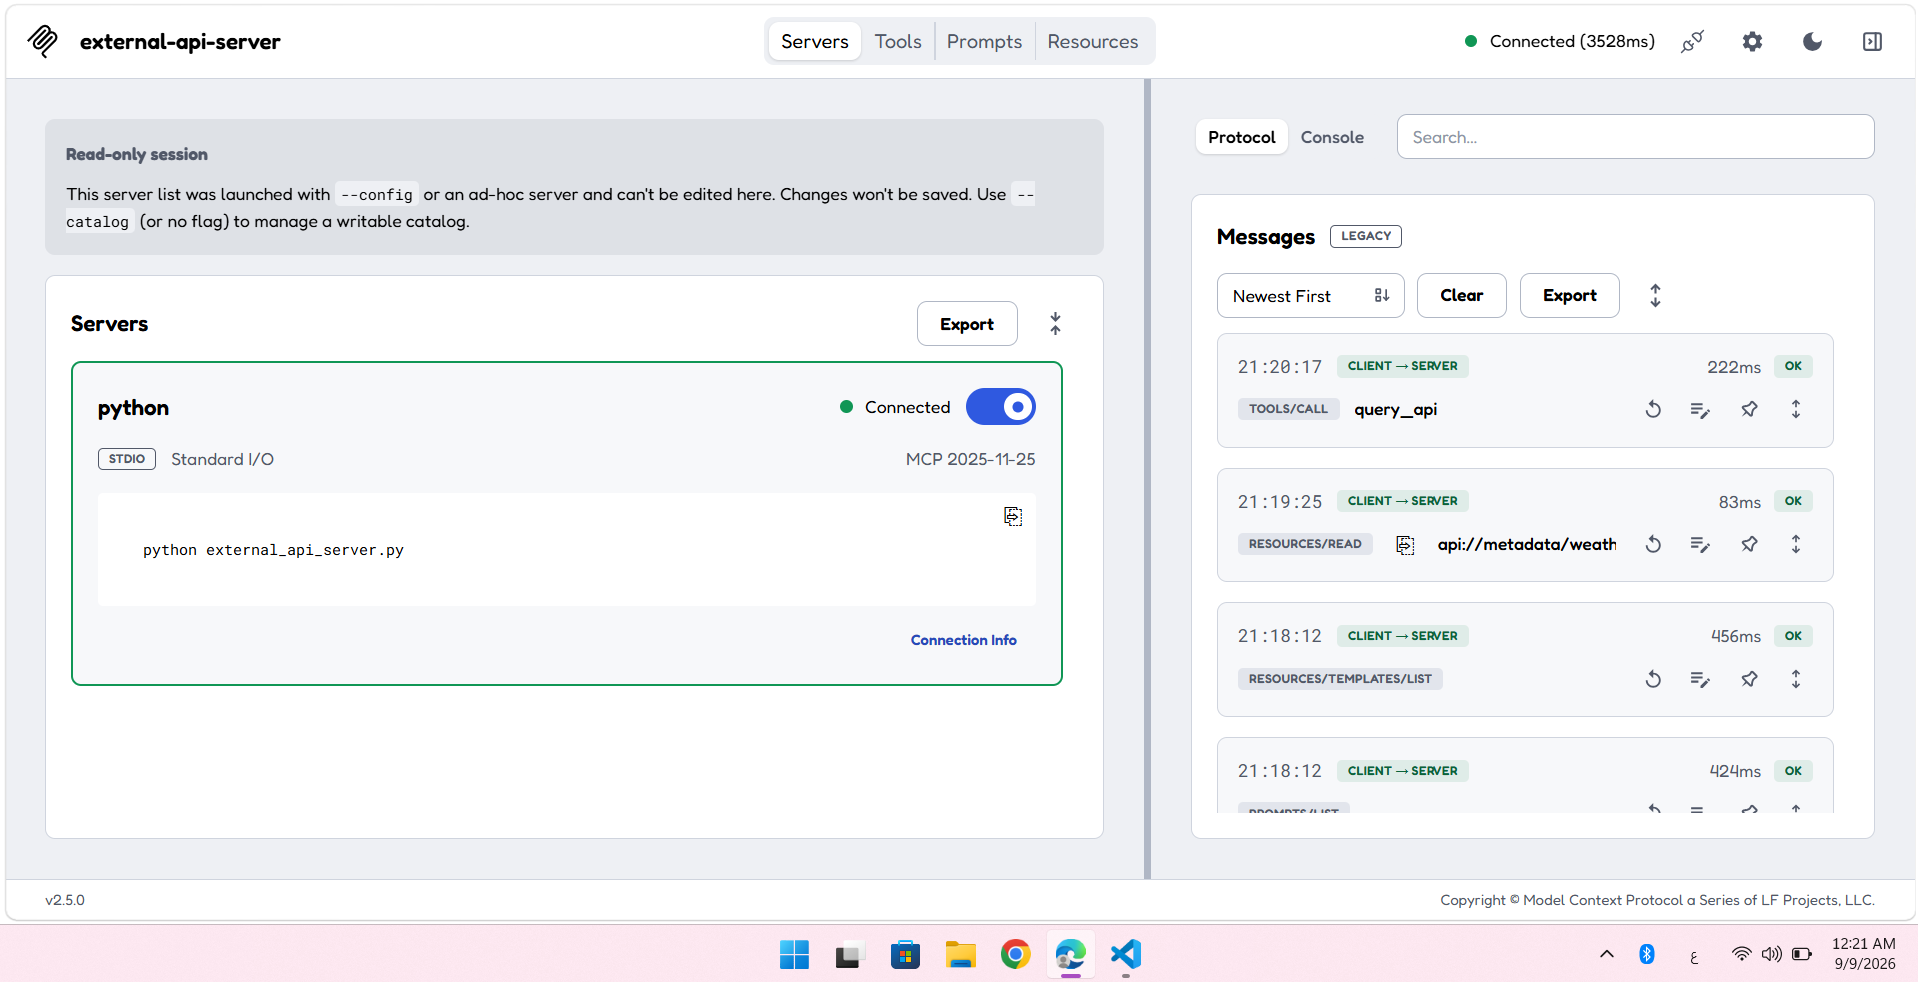

- The 4 metadata resources are available.
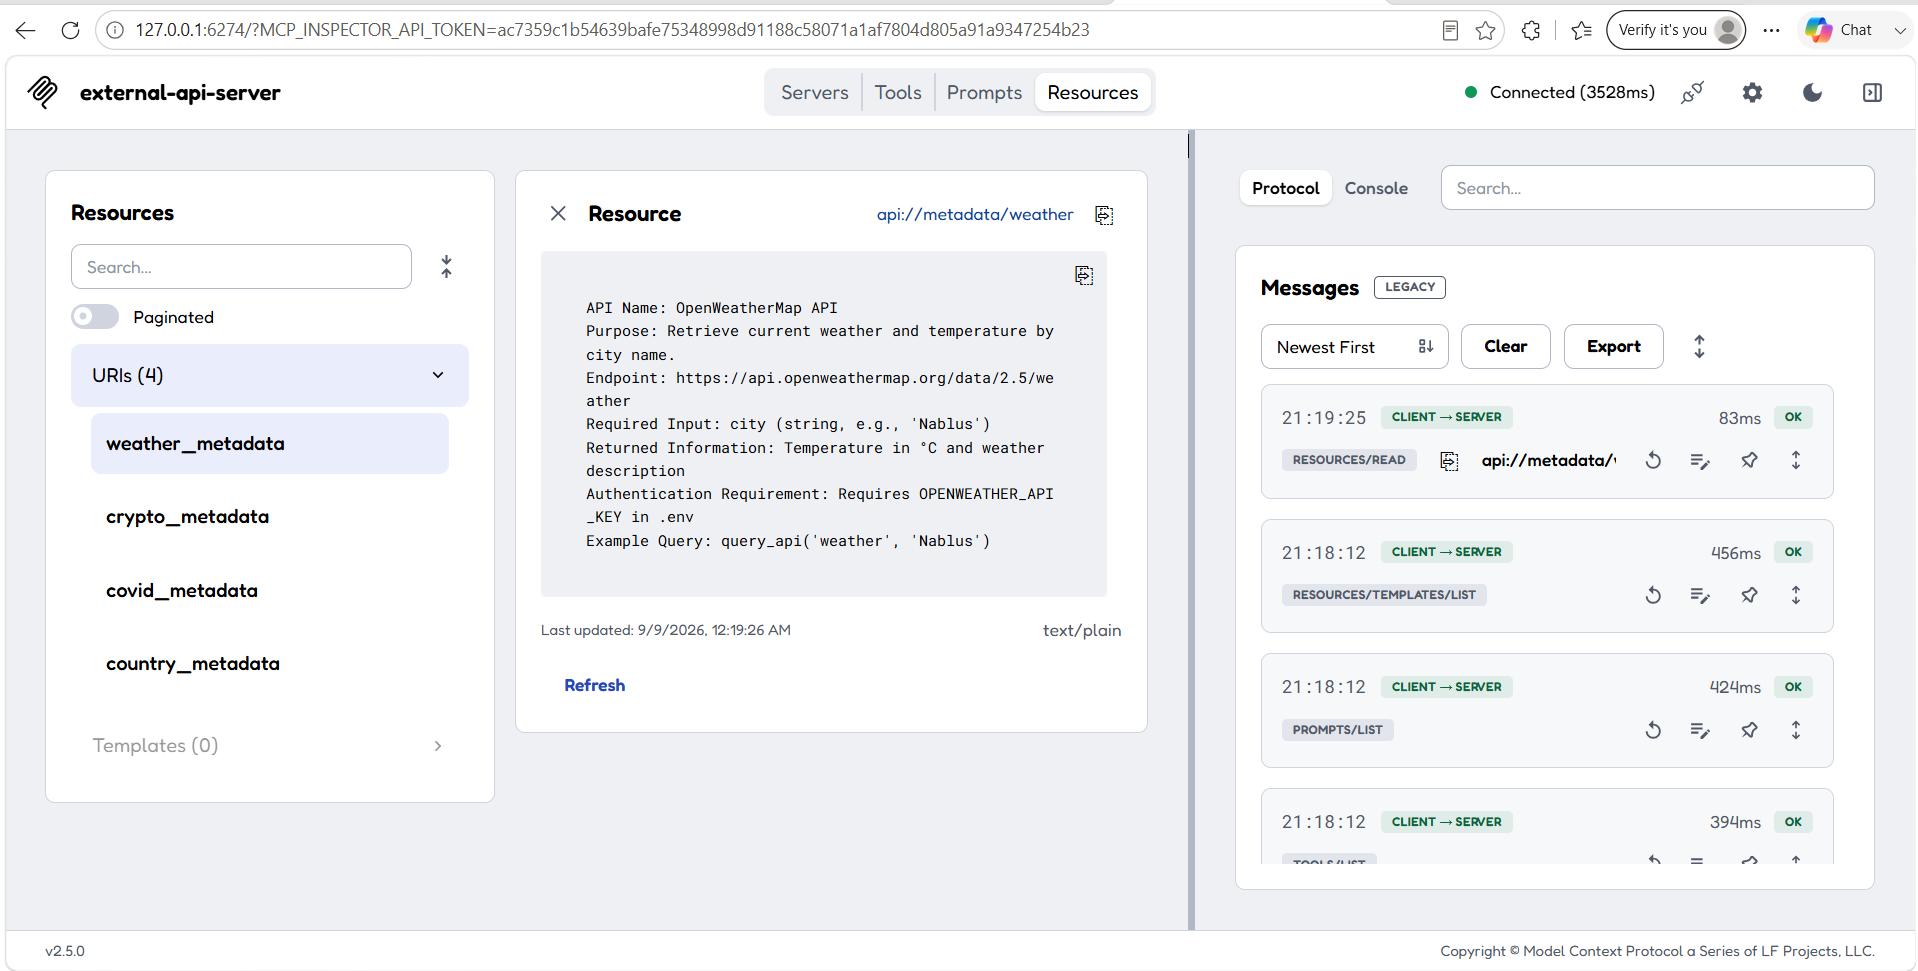

- `query_api` works with an example such as crypto → bitcoin.

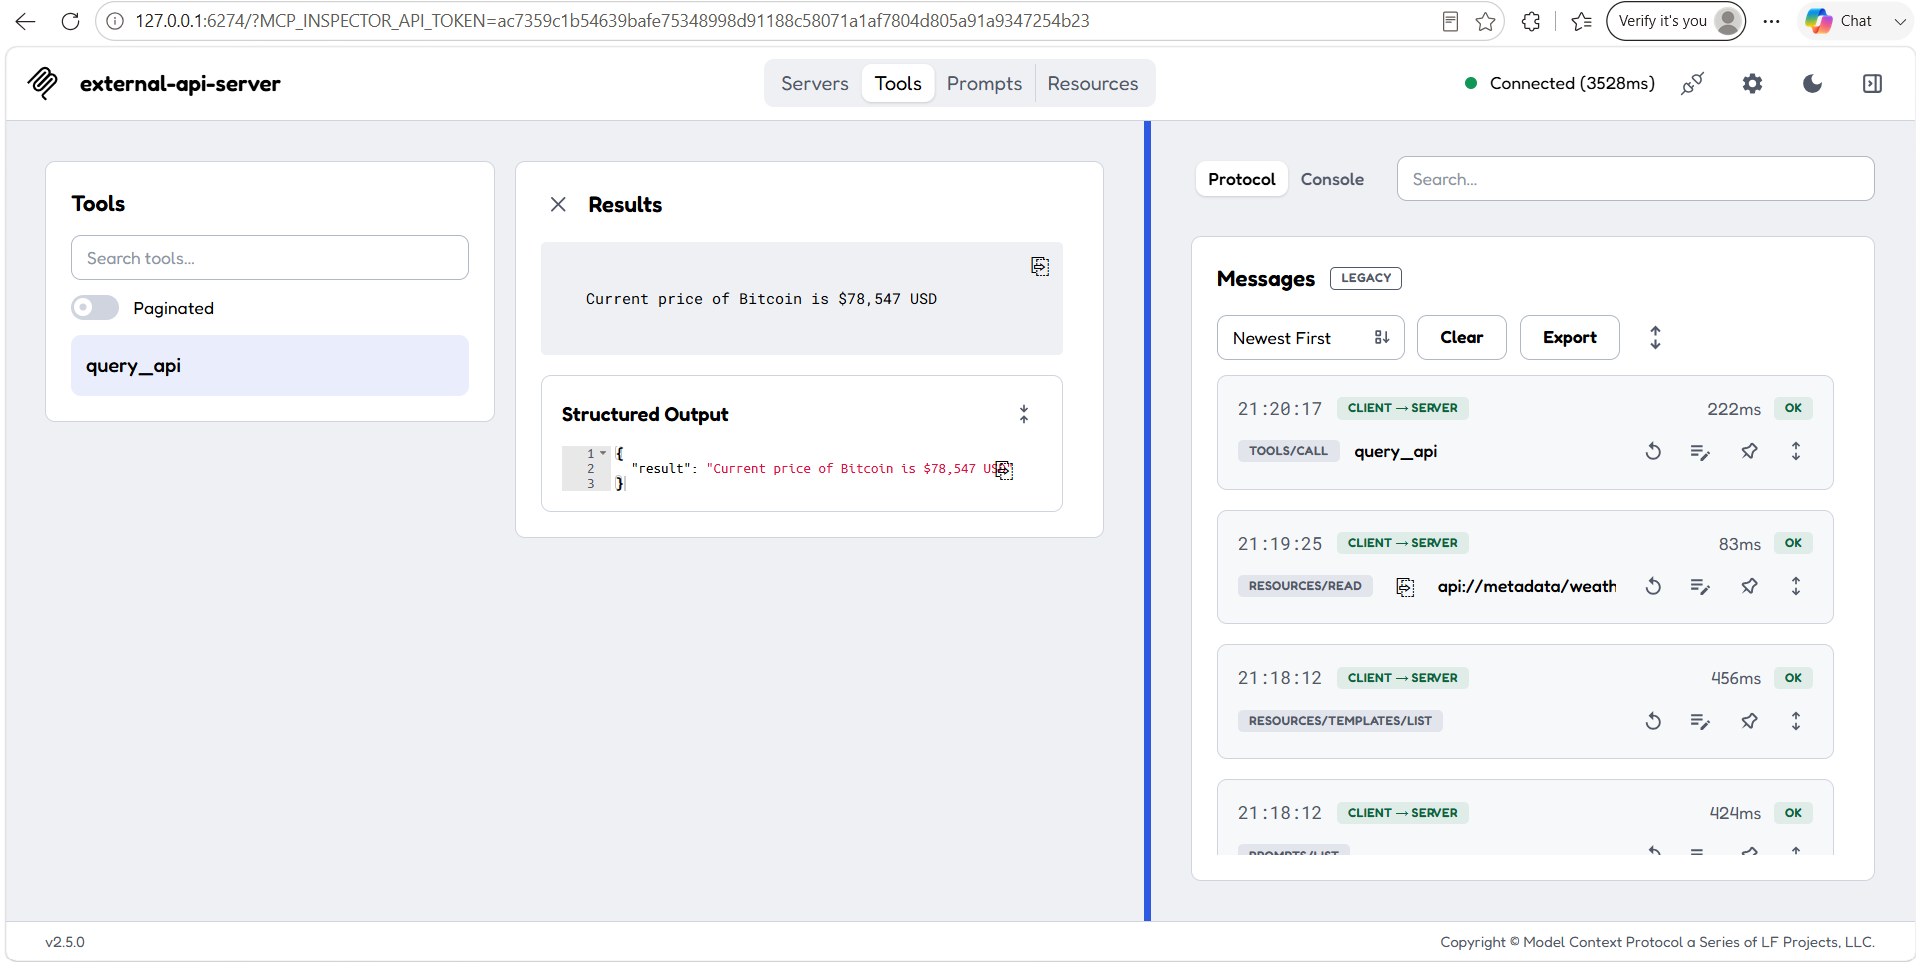

### 5.3 MCP Inspector Testing Instructions
Run the MCP server using MCP Inspector:

```bash
npx @modelcontextprotocol/inspector python external_api_server.py
```

Check that:

- The server connects successfully.
![image-3.png](attachment:image-3.png)

- The 4 metadata resources are available.
![image.png](attachment:image.png)

- `query_api` works with an example such as crypto → bitcoin.

![image-2.png](attachment:image-2.png)